# Lab2 presenter guide
**Authors:** Thai Binh Nguyen and Ege Deniz

Viewing copy with saved outputs. Execute `lab2.ipynb`, not this copy. Target **4:40**.

| Time | Show | Explain |
|---|---|---|
| 0:00–0:25 | Task and data | Authors, 48k/6k/6k split |
| 0:25–1:05 | Baseline and training | Encoder, 1,024 latent values, decoder, automatic gradients |
| 1:05–2:20 | Design table and report Figures 1–2 | Width vs matched parameters; same-latent structural changes; three seeds |
| 2:20–3:35 | Colour setup and Figures 4–5 | RGB vs chroma; colour-only error; colour strength |
| 3:35–4:15 | Failure panel and report | Ambiguity; fixed budget; reused test split |
| 4:15–4:40 | Conclusion | Measured answers, compression trade-off, limitations |

Both authors should understand the code and results. Switch speakers after reconstruction if sharing narration.
Briefly show both code and report. Record and upload the actual video; this notebook does not replace it.

# ACML Assignment 2: Convolutional Autoencoders
**Authors:** Thai Binh Nguyen and Ege Deniz

Reconstruct CIFAR-10 images, compare latent sizes, and colourise grayscale inputs.

## 1. Setup
Run all cells from this notebook's folder. The first run downloads CIFAR-10.
Dependencies: `torch`, `torchvision`, `numpy`, `pandas`, `matplotlib`.
Results and checkpoints are saved under `results/`; completed runs are reused.
Set `RETRAIN = True` to rerun all experiments. CPU is supported but slower.

In [1]:
from pathlib import Path
import copy
import json
import math
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torchvision.datasets import CIFAR10
from IPython.display import display

SEEDS = [0, 1, 2]
SPLIT_SEED = 42
EPOCHS = 20
BATCH_SIZE = 256
LEARNING_RATE = 1e-3
RETRAIN = False
ROOT = Path.cwd()
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(min(4, torch.get_num_threads()))
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

environment = {"torch": torch.__version__, "numpy": np.__version__,
               "device": str(device), "seeds": SEEDS, "split_seed": SPLIT_SEED,
               "epochs": EPOCHS, "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE}
if device.type == "cuda":
    environment["gpu"] = torch.cuda.get_device_name(0)
(RESULTS / "environment.json").write_text(json.dumps(environment, indent=2))
print(f"Device: {device} | Epochs: {EPOCHS} | Seeds: {SEEDS}")

Device: cuda | Epochs: 20 | Seeds: [0, 1, 2]


## 2. Data and fixed split
Combine the 60,000 CIFAR-10 images and create a new stratified **80/10/10** split:
48,000 training, 6,000 validation, 6,000 test. This is our lab split, not the official benchmark split.
Labels are used only to balance the split and describe results; they are never model inputs or targets.
Pixels are divided by 255. Validation selects models; test evaluation occurs after all choices are frozen.

Toronto was unavailable for this run. The optional mirror cache was downloaded from `uoft-cs/cifar10` and each parquet file was SHA-256 verified. Use `verification/download_mirror.py` if the default download fails.

In [2]:
cache_path = ROOT / "data" / "cifar10_rgb.npz"
if cache_path.exists():

    with np.load(cache_path) as cache:
        images, labels = cache["images"], cache["labels"]
    class_names = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
else:
    source_train = CIFAR10(ROOT / "data", train=True, download=True)
    source_test = CIFAR10(ROOT / "data", train=False, download=True)
    images = np.concatenate([source_train.data, source_test.data])
    labels = np.array(source_train.targets + source_test.targets)
    class_names = source_train.classes
assert images.shape == (60000, 32, 32, 3)
assert np.array_equal(np.bincount(labels), np.full(10, 6000))
rng = np.random.default_rng(SPLIT_SEED)
split_indices = {"train": [], "val": [], "test": []}
for label in range(10):
    indices = rng.permutation(np.flatnonzero(labels == label))
    split_indices["train"].extend(indices[:4800])
    split_indices["val"].extend(indices[4800:5400])
    split_indices["test"].extend(indices[5400:])
split_indices = {name: rng.permutation(indices) for name, indices in split_indices.items()}
assert sum(map(len, split_indices.values())) == len(images) == 60000
assert len(set(np.concatenate(list(split_indices.values())))) == 60000
np.savez(RESULTS / "split_indices.npz", **split_indices)

def image_tensor(indices):
    array = np.ascontiguousarray(images[indices].transpose(0, 3, 1, 2))
    return torch.from_numpy(array).to(device=device, dtype=torch.float32) / 255.0

train_rgb = image_tensor(split_indices["train"])
val_rgb = image_tensor(split_indices["val"])
print("Train / validation / test:", *(len(split_indices[name]) for name in ["train", "val", "test"]))

Train / validation / test: 48000 6000 6000


## 3. Baseline architecture — Exercise 1
`Conv(8) → Pool → Conv(12) → Pool → Conv(16) → Up → Conv(12) → Up → Conv(3)`.
All convolutions use 3×3 kernels, stride 1 and padding 1. Pooling and nearest-neighbour upsampling use factor 2.
Hidden activations are ReLU; output sigmoid matches pixels in [0,1].
The central convolution defines the latent tensor: **16×8×8 = 1,024 values**, versus 3,072 input values.
The preceding pooled tensor has 12×8×8 = 768 values; we report the central convolution's output consistently.

> **SAY:** The prescribed network has 4,911 parameters. The central latent is 16 by 8 by 8, or 1,024 values; the preceding pool has 768. The decoder upsamples and reconstructs RGB.

In [3]:
class ConvAutoencoder(nn.Module):
    def __init__(self, channels=(8, 12, 16), input_channels=3, output_channels=3,
                 chroma_output=False, latent_side=8, kernel_size=3,
                 downsample="pool", extra_latent_layer=False):
        super().__init__()
        first, second, latent = channels
        assert latent_side in (4, 8, 16)
        assert downsample in ("pool", "stride")
        assert downsample != "stride" or latent_side == 8
        padding = kernel_size // 2
        stride = 2 if downsample == "stride" else 1
        pool1 = nn.Identity() if downsample == "stride" else nn.MaxPool2d(2)
        pool2 = nn.Identity() if downsample == "stride" else nn.MaxPool2d(16 // latent_side)
        encoder_layers = [
            nn.Conv2d(input_channels, first, kernel_size, stride=stride, padding=padding), nn.ReLU(),
            pool1,
            nn.Conv2d(first, second, kernel_size, stride=stride, padding=padding), nn.ReLU(),
            pool2,
            nn.Conv2d(second, latent, kernel_size, padding=padding), nn.ReLU(),
        ]
        if extra_latent_layer:
            encoder_layers.extend([nn.Conv2d(latent, latent, kernel_size, padding=padding), nn.ReLU()])
        self.encoder = nn.Sequential(*encoder_layers)
        self.decoder = nn.Sequential(
            nn.Upsample(scale_factor=16 // latent_side, mode="nearest"),
            nn.Conv2d(latent, second, kernel_size, padding=padding), nn.ReLU(),
            nn.Upsample(scale_factor=2, mode="nearest"),
            nn.Conv2d(second, output_channels, kernel_size, padding=padding),
            nn.Tanh() if chroma_output else nn.Sigmoid(),
        )

    def forward(self, inputs):
        return self.decoder(self.encoder(inputs))

def grayscale(rgb):
    weights = rgb.new_tensor([0.299, 0.587, 0.114]).view(1, 3, 1, 1)
    return (rgb * weights).sum(dim=1, keepdim=True)

def build_model(config):
    task = config["task"]
    return ConvAutoencoder(
        tuple(config["channels"]), input_channels=3 if task == "reconstruction" else 1,
        output_channels=2 if task == "chroma" else 3,
        chroma_output=task == "chroma", latent_side=config.get("latent_side", 8),
        kernel_size=config.get("kernel_size", 3), downsample=config.get("downsample", "pool"),
        extra_latent_layer=config.get("extra_latent_layer", False),
    ).to(device)

def predict_rgb(model, rgb, task):
    if task == "reconstruction":
        return model(rgb)
    luminance = grayscale(rgb)
    output = model(luminance)
    if task == "color_rgb":
        return output
    cb, cr = (0.5 * output).split(1, dim=1)
    red = luminance + 1.402 * cr
    green = luminance - 0.344136 * cb - 0.714136 * cr
    blue = luminance + 1.772 * cb
    return torch.cat([red, green, blue], dim=1).clamp(0, 1)

## 4. Training and validation
Adam, learning rate 0.001, batch size 256, **20 epochs per run**. RGB MSE averages images, channels and pixels.
Each configuration uses **three seeds (0, 1, 2)** and the same split. Save the lowest-validation-MSE checkpoint.
No augmentation, scheduler or early stopping. Architecture choices use validation means, never test rankings.

> **SAY:** Each model gets twenty epochs, the same split and three seeds. PyTorch computes gradients. Validation selects checkpoints and architectures; test rankings do not choose models.

In [4]:
loss_function = nn.MSELoss()

@torch.no_grad()
def evaluate(model, rgb, task):
    model.eval()
    squared_errors = []
    for batch in rgb.split(BATCH_SIZE):
        prediction = predict_rgb(model, batch, task)
        squared_errors.append((prediction - batch).square().mean(dim=(1, 2, 3)).cpu())
    return torch.cat(squared_errors)

def train_run(config, seed):
    run_id = f"{config['name']}_seed{seed}"
    checkpoint_path = RESULTS / f"{run_id}.pt"
    expected = {**config, "seed": seed, "epochs": EPOCHS,
                "batch_size": BATCH_SIZE, "lr": LEARNING_RATE, "split_seed": SPLIT_SEED}
    if checkpoint_path.exists() and not RETRAIN:
        saved = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
        if saved["settings"] == expected:
            return saved["row"], saved["history"]
    set_seed(seed)
    model = build_model(config)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history = []
    best_val = float("inf")
    best_state = None
    start = time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        model.train()
        permutation = torch.randperm(len(train_rgb), device=device)
        training_sum = 0.0
        for indices in permutation.split(BATCH_SIZE):
            batch = train_rgb[indices]
            optimizer.zero_grad(set_to_none=True)
            prediction = predict_rgb(model, batch, config["task"])
            loss = loss_function(prediction, batch)
            if not torch.isfinite(loss):
                raise RuntimeError(f"Non-finite loss: {run_id}")
            loss.backward()
            optimizer.step()
            training_sum += loss.item() * len(batch)
        val_mse = evaluate(model, val_rgb, config["task"]).mean().item()
        history.append({"epoch": epoch, "train_mse": training_sum / len(train_rgb),
                        "val_mse": val_mse})
        if val_mse < best_val:
            best_val, best_epoch = val_mse, epoch
            best_state = {key: value.detach().cpu().clone()
                          for key, value in model.state_dict().items()}
        with (RESULTS / "progress.log").open("a", encoding="utf-8") as log:
            log.write(f"{run_id} epoch={epoch} train={history[-1]['train_mse']:.6f} val={val_mse:.6f}\n")
    if device.type == "cuda":
        torch.cuda.synchronize()
    row = {"name": config["name"], "task": config["task"], "seed": seed,
           "channels": "-".join(map(str, config["channels"])),
           "latent_values": config["channels"][-1] * config.get("latent_side", 8) ** 2,
           "latent_side": config.get("latent_side", 8),
           "kernel_size": config.get("kernel_size", 3),
           "downsample": config.get("downsample", "pool"),
           "extra_latent_layer": config.get("extra_latent_layer", False),
           "parameters": sum(p.numel() for p in model.parameters()),
           "best_epoch": best_epoch, "val_mse": best_val,
           "seconds": time.perf_counter() - start}
    torch.save({"settings": expected, "state_dict": best_state,
                "row": row, "history": history}, checkpoint_path)
    pd.DataFrame(history).to_csv(RESULTS / f"{run_id}_history.csv", index=False)
    return row, history

def load_run(config, seed):
    saved = torch.load(RESULTS / f"{config['name']}_seed{seed}.pt",
                       map_location="cpu", weights_only=False)
    model = build_model(config)
    model.load_state_dict(saved["state_dict"])
    model.eval()
    return model

## 5. Architecture experiments — Exercises 1 and 2
Eight pre-specified configurations; the baseline anchors each contrast:

| Contrast | Configurations | Question |
|---|---|---|
| Width | narrow / baseline / wide | Does adding channels improve reconstruction? |
| Spatial bottleneck, matched parameters | spatial4 / baseline / spatial16 | What changes when latent resolution changes at fixed learned parameter count? |
| Downsampling | baseline / strided | Max pooling versus stride-2 convolutions |
| Depth | baseline / deeper | One extra convolution at unchanged latent shape |
| Kernel | baseline / kernel5 | 3×3 versus 5×5 kernels |

The spatial contrast keeps channels and all learned weight shapes fixed. It changes second pooling and matching upsampling:
latent tensors are 16×4×4, 16×8×8 and 16×16×16, with **4,911 parameters each**.
The central 4,096-value spatial16 representation is **overcomplete**, but the encoder still passes through a smaller 2,048-value layer.
Spatial resolution also changes sampling and computation, so this is not a proof that dimension alone causes the effect.
All designs and the 20-epoch budget are fixed before the expanded test evaluation.

> **SAY:** The width comparison changes parameters as well as latent size. The stronger control keeps 4,911 learned parameters while changing spatial resolution. The 4,096-value central code is overcomplete, but it still comes from an earlier 2,048-value bottleneck. Do not confuse those quantities.

In [5]:
reconstruction_configs = [
    {"name": "narrow", "task": "reconstruction", "channels": [4, 6, 8]},
    {"name": "baseline", "task": "reconstruction", "channels": [8, 12, 16]},
    {"name": "wide", "task": "reconstruction", "channels": [16, 24, 32]},
    {"name": "spatial4", "task": "reconstruction", "channels": [8, 12, 16], "latent_side": 4},
    {"name": "spatial16", "task": "reconstruction", "channels": [8, 12, 16], "latent_side": 16},
    {"name": "strided", "task": "reconstruction", "channels": [8, 12, 16], "downsample": "stride"},
    {"name": "deeper", "task": "reconstruction", "channels": [8, 12, 16], "extra_latent_layer": True},
    {"name": "kernel5", "task": "reconstruction", "channels": [8, 12, 16], "kernel_size": 5},
]

architecture_rows = []
for config in reconstruction_configs:
    model = build_model(config)
    with torch.no_grad():
        probe = train_rgb[:2]
        features = probe
        encoder_sizes = []
        for layer in model.encoder:
            features = layer(features)
            encoder_sizes.append(features[0].numel())
        latent_shape = tuple(features.shape[1:])
        assert model(probe).shape == probe.shape
    architecture_rows.append({
        "name": config["name"], "channels": str(config["channels"]),
        "latent_shape": "×".join(map(str, latent_shape)), "latent_values": math.prod(latent_shape),
        "smallest_encoder_values": min(encoder_sizes),
        "parameters": sum(p.numel() for p in model.parameters()),
        "kernel": config.get("kernel_size", 3), "downsample": config.get("downsample", "pool"),
        "extra_layer": config.get("extra_latent_layer", False),
    })
architecture_table = pd.DataFrame(architecture_rows)
matched = architecture_table[architecture_table.name.isin(["spatial4", "baseline", "spatial16"])]
assert matched.parameters.nunique() == 1
assert matched.latent_values.nunique() == 3
architecture_table.to_csv(RESULTS / "architecture_design.csv", index=False)
display(architecture_table)
del model

run_rows, histories = [], {}
for config in reconstruction_configs:
    for seed in SEEDS:
        row, history = train_run(config, seed)
        run_rows.append(row)
        histories[(config["name"], seed)] = history

reconstruction_validation = pd.DataFrame(run_rows)
validation_ranking = reconstruction_validation.groupby("name")["val_mse"].mean().sort_values()
best_reconstruction_name = validation_ranking.index[0]
best_reconstruction_config = next(c for c in reconstruction_configs if c["name"] == best_reconstruction_name)
print("Best architecture by mean validation MSE:", best_reconstruction_name)

,name,channels,latent_shape,latent_values,smallest_encoder_values,parameters,kernel,downsample,extra_layer
0,narrow,"[4, 6, 8]",8×8×8,512,384,1377,3,pool,False
1,baseline,"[8, 12, 16]",16×8×8,1024,768,4911,3,pool,False
2,wide,"[16, 24, 32]",32×8×8,2048,1536,18459,3,pool,False
3,spatial4,"[8, 12, 16]",16×4×4,256,192,4911,3,pool,False
4,spatial16,"[8, 12, 16]",16×16×16,4096,2048,4911,3,pool,False
5,strided,"[8, 12, 16]",16×8×8,1024,768,4911,3,stride,False
6,deeper,"[8, 12, 16]",16×8×8,1024,768,7231,3,pool,True
7,kernel5,"[8, 12, 16]",16×8×8,1024,768,13551,5,pool,False


Best architecture by mean validation MSE: spatial16


## 6. Colourisation — Exercise 3
Start from the best reconstruction architecture and train fresh weights; the grayscale input has one channel.
**Direct RGB:** predict all three channels. **Chroma:** predict two bounded Cb/Cr channels and combine them with input luminance.
Both optimize the same RGB MSE. The chroma model preserves luminance before RGB clipping; clipping may change it slightly.
This uses paired grayscale/colour targets derived from the same image; no category labels are needed.

> **SAY:** We inherit the complete best reconstruction architecture, not just its channels. Direct RGB predicts everything. Chroma predicts two colour components and reuses input luminance. Both optimize RGB MSE.

In [6]:
color_configs = [
    {**best_reconstruction_config, "name": "color_rgb", "task": "color_rgb"},
    {**best_reconstruction_config, "name": "color_chroma", "task": "chroma"},
]
for config in color_configs:
    for seed in SEEDS:
        row, history = train_run(config, seed)
        run_rows.append(row)
        histories[(config["name"], seed)] = history

runs = pd.DataFrame(run_rows)
color_ranking = runs[runs.task != "reconstruction"].groupby("name")["val_mse"].mean().sort_values()
best_color_name = color_ranking.index[0]
configs = reconstruction_configs + color_configs
selected_seeds = {
    c["name"]: int(runs[runs.name == c["name"]].sort_values(["val_mse", "seed"]).iloc[0]["seed"])
    for c in configs
}
selection = {"best_reconstruction": best_reconstruction_name, "best_color": best_color_name,
             "selected_seeds": selected_seeds, "rule": "Mean validation MSE selects architecture; validation MSE selects display seed."}
(RESULTS / "selection.json").write_text(json.dumps(selection, indent=2))
print("Selected on validation:", best_reconstruction_name, "| Colourisation:", best_color_name)

Selected on validation: spatial16 | Colourisation: color_chroma


## 7. Held-out evaluation
Choices are frozen using validation before evaluating these expanded experiments on test data.
The same test split appeared in the initial exploratory version; it is not a new independent replication.
Test scores are descriptive and do not select configurations. The grayscale baseline copies luminance into R, G and B.
PSNR = −10 log10(dataset MSE), with pixel range 1; it is not the mean per-image PSNR.

> **SAY:** Validation selects spatial16 for reconstruction and color_chroma for colourisation. The selected colour model has 19.9% lower test MSE than copying grayscale. The test split was also used in the initial exploratory version, so this is not independent replication.

In [7]:
test_rgb = image_tensor(split_indices["test"])
test_errors = {}
for config in configs:
    for seed in SEEDS:
        model = load_run(config, seed)
        errors = evaluate(model, test_rgb, config["task"])
        test_errors[(config["name"], seed)] = errors.numpy()
        mask = (runs.name == config["name"]) & (runs.seed == seed)
        mse = errors.mean().item()
        runs.loc[mask, "test_mse"] = mse
        runs.loc[mask, "test_psnr"] = -10 * math.log10(mse)
        del model

gray_errors = (grayscale(test_rgb).expand(-1, 3, -1, -1) - test_rgb).square().mean((1, 2, 3)).cpu().numpy()
gray_mse = float(gray_errors.mean())
runs.to_csv(RESULTS / "experiment_runs.csv", index=False)
summary = runs.groupby(["name", "task", "latent_values", "parameters"], sort=False).agg(
    val_mse=("val_mse", "mean"), test_mse=("test_mse", "mean"),
    test_mse_sd=("test_mse", "std"), test_psnr=("test_psnr", "mean"),
    seconds=("seconds", "mean"),
).reset_index()
summary.to_csv(RESULTS / "experiment_summary.csv", index=False)
(RESULTS / "gray_baseline.json").write_text(json.dumps({"test_mse": gray_mse,
    "test_psnr": -10 * math.log10(gray_mse)}, indent=2))
display(summary.round(6))
print(f"Untrained grayscale baseline: MSE={gray_mse:.6f}, PSNR={-10*math.log10(gray_mse):.2f} dB")

,name,task,latent_values,parameters,val_mse,test_mse,test_mse_sd,test_psnr,seconds
0,narrow,reconstruction,512,1377,0.007272,0.007207,0.000156,21.422856,12.288761
1,baseline,reconstruction,1024,4911,0.005667,0.005629,0.000396,22.502720,19.453174
2,wide,reconstruction,2048,18459,0.004332,0.004310,0.000228,23.659651,27.607179
3,spatial4,reconstruction,256,4911,0.013446,0.013362,0.000308,18.742064,18.057154
4,spatial16,reconstruction,4096,4911,0.002325,0.002314,0.000306,26.382056,19.270503
5,strided,reconstruction,1024,4911,0.004240,0.004211,0.000201,23.759447,17.127142
6,deeper,reconstruction,1024,7231,0.005734,0.005688,0.000294,22.454600,20.806978
7,kernel5,reconstruction,1024,13551,0.005593,0.005552,0.000236,22.558068,26.751578
8,color_rgb,color_rgb,4096,4767,0.007201,0.007234,0.000091,21.406627,19.136701
9,color_chroma,chroma,4096,4658,0.005255,0.005262,0.000017,22.788546,20.470366


Untrained grayscale baseline: MSE=0.006568, PSNR=21.83 dB


## 8. Learning curves and fixed examples
Curves show means over three seeds and validation SD bands, grouped by experimental question.
Image panels use the first eight test images in the unchanged fixed split order, not selected successes.
Numbers above images are original dataset indices.

> **SAY:** The curves show means over three seeds and validation standard-deviation bands. The image columns are the first eight test images, not selected successes. Report Figure 2 separates width from the parameter-matched spatial comparison.

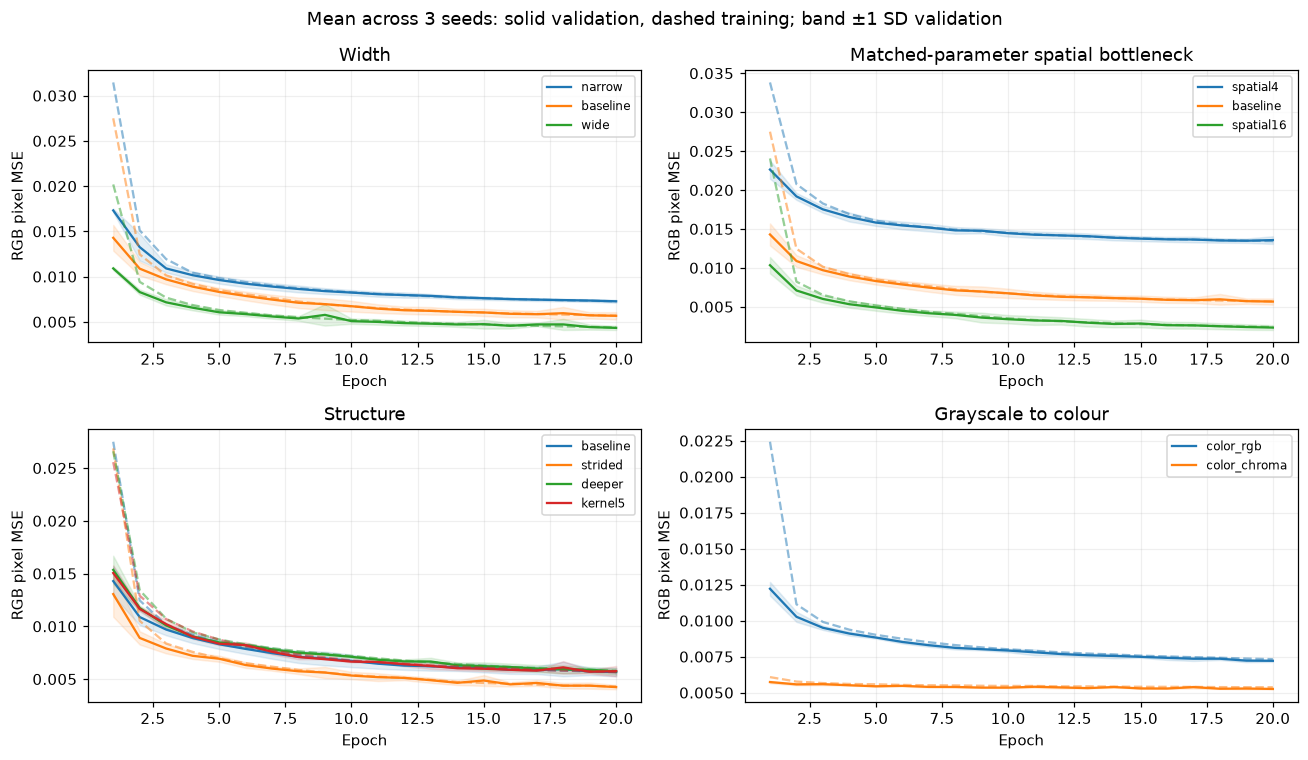

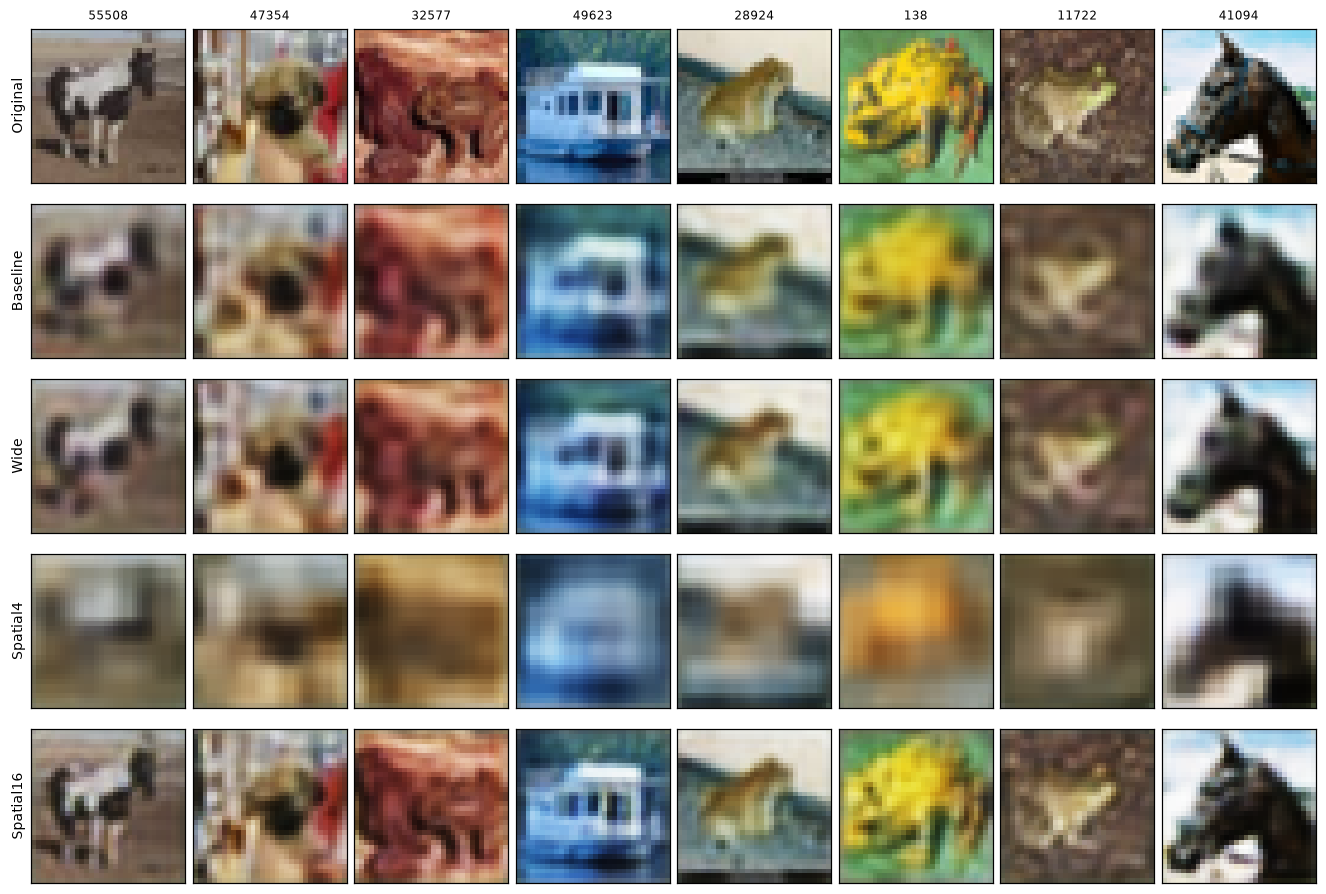

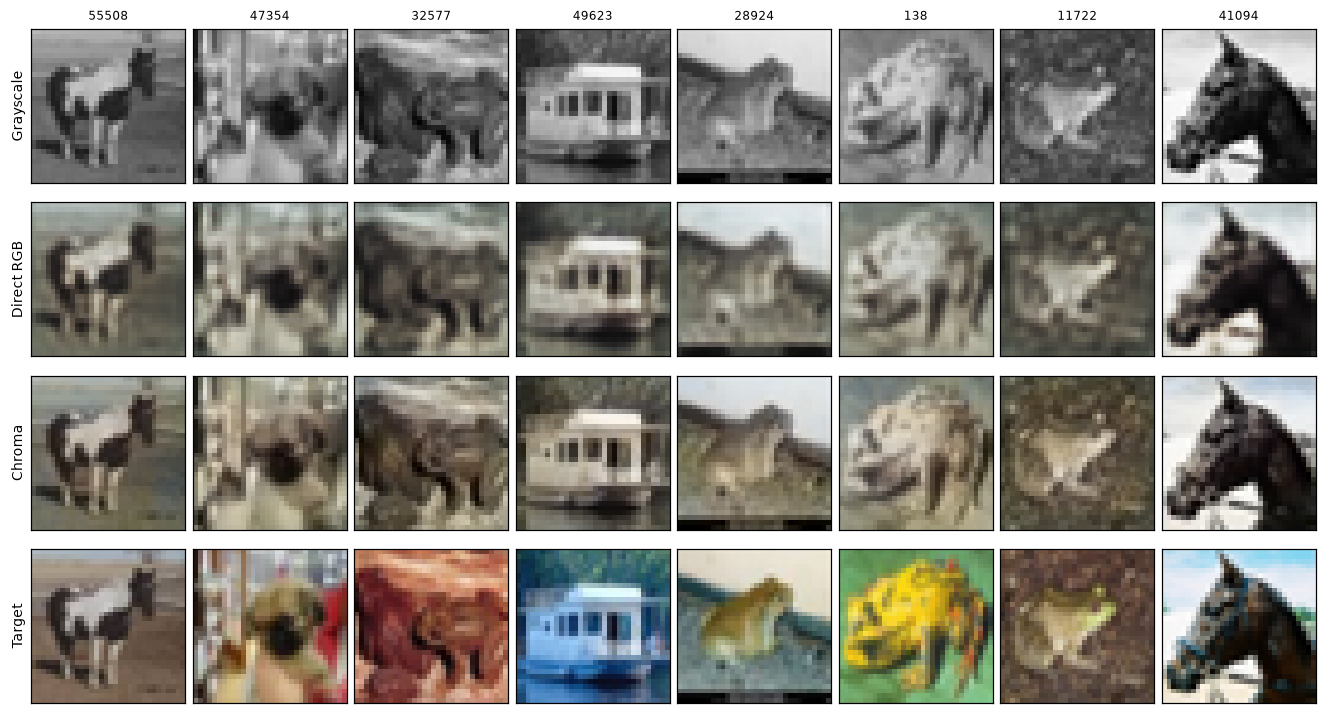

In [8]:
plt.rcParams.update({"font.size": 10, "figure.dpi": 110})
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
groups = [
    ("Width", ["narrow", "baseline", "wide"]),
    ("Matched-parameter spatial bottleneck", ["spatial4", "baseline", "spatial16"]),
    ("Structure", ["baseline", "strided", "deeper", "kernel5"]),
    ("Grayscale to colour", ["color_rgb", "color_chroma"]),
]
for ax, (title, names) in zip(axes.flat, groups):
    for name in names:
        values = np.array([[r["val_mse"] for r in histories[(name, seed)]] for seed in SEEDS])
        training = np.array([[r["train_mse"] for r in histories[(name, seed)]] for seed in SEEDS])
        epochs = np.arange(1, EPOCHS + 1)
        line, = ax.plot(epochs, values.mean(0), label=name)
        ax.fill_between(epochs, values.mean(0)-values.std(0, ddof=1),
                        values.mean(0)+values.std(0, ddof=1), color=line.get_color(), alpha=0.12)
        ax.plot(epochs, training.mean(0), "--", color=line.get_color(), alpha=0.5)
    ax.set(title=title, xlabel="Epoch", ylabel="RGB pixel MSE")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
fig.suptitle("Mean across 3 seeds: solid validation, dashed training; band ±1 SD validation")
fig.tight_layout()
fig.savefig(RESULTS / "learning_curves.png", dpi=180, bbox_inches="tight")
plt.show()

@torch.no_grad()
def predicted_images(name, positions):
    config = next(c for c in configs if c["name"] == name)
    model = load_run(config, selected_seeds[name])
    output = predict_rgb(model, test_rgb[positions], config["task"]).cpu()
    del model
    return output

def image_grid(rows, names, positions, filename):
    fig, axes = plt.subplots(len(rows), len(positions), figsize=(12, 1.65 * len(rows)), squeeze=False)
    for row, (batch, name) in enumerate(zip(rows, names)):
        for col in range(len(positions)):
            ax = axes[row, col]
            ax.imshow(batch[col].permute(1, 2, 0).numpy().clip(0, 1), interpolation="nearest")
            ax.set_xticks([]); ax.set_yticks([])
            if row == 0:
                index = split_indices["test"][positions[col]]
                ax.set_title(str(index), fontsize=8)
            if col == 0:
                ax.set_ylabel(name, fontsize=9)
    fig.tight_layout(pad=0.5)
    fig.savefig(RESULTS / filename, dpi=180, bbox_inches="tight")
    plt.show()

positions = list(range(8))
originals = test_rgb[positions].cpu()
image_grid([originals] + [predicted_images(name, positions) for name in ["baseline", "wide", "spatial4", "spatial16"]],
           ["Original", "Baseline", "Wide", "Spatial4", "Spatial16"], positions, "reconstruction_examples.png")
image_grid([grayscale(originals).expand(-1, 3, -1, -1),
            predicted_images("color_rgb", positions), predicted_images("color_chroma", positions), originals],
           ["Grayscale", "Direct RGB", "Chroma", "Target"], positions, "colorization_examples.png")

## 9. Error analysis
Show the eight highest-MSE test images for the validation-selected colourisation model, explicitly selected as failures.
Class labels are used for analysis only. Average errors describe this split, not the whole population.

> **SAY:** This panel deliberately shows the largest errors. Grayscale does not identify unique colours, and MSE can favour desaturated averages. Lower MSE does not mean that every true hue has been recovered.

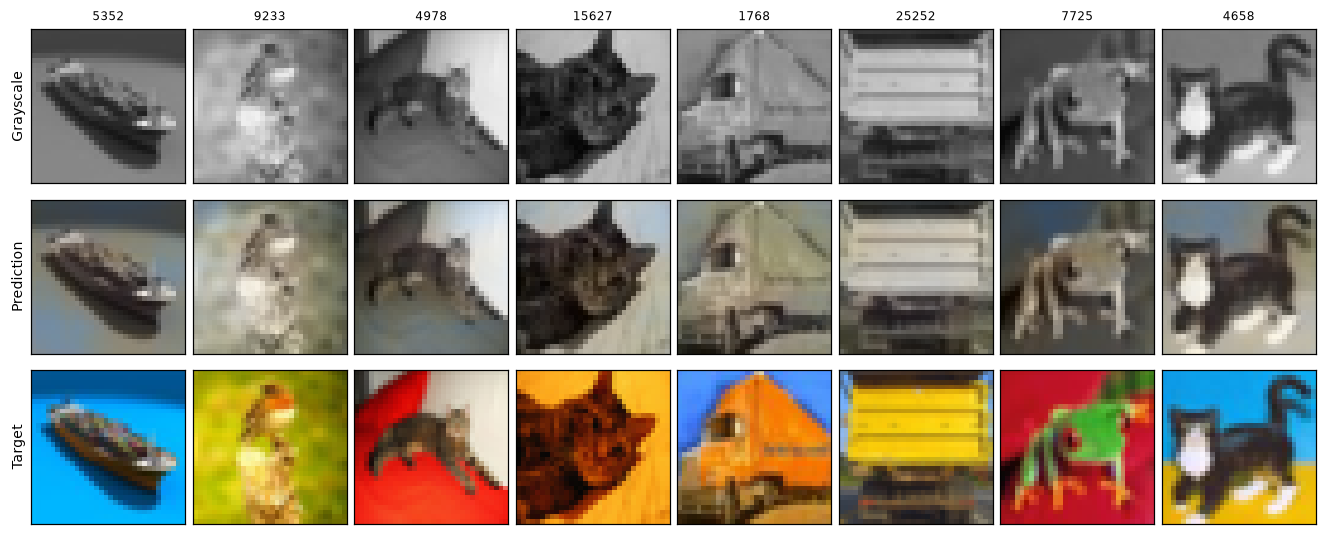

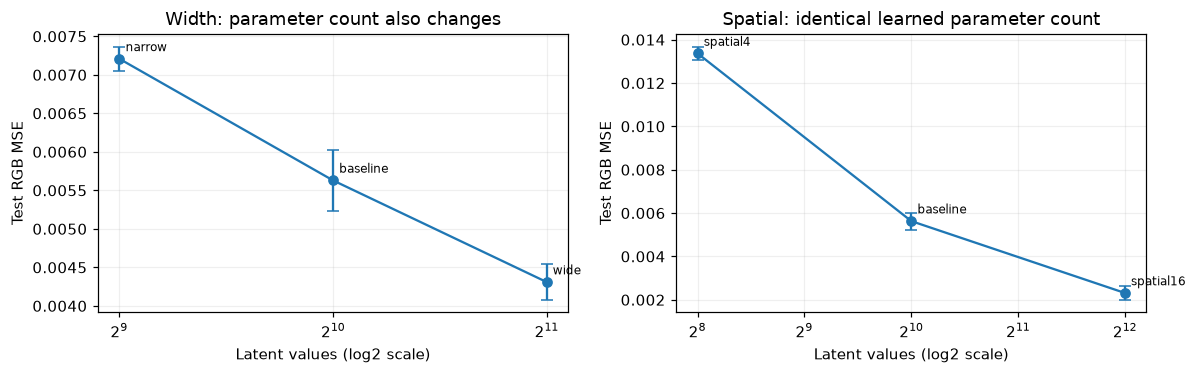

In [9]:
chosen_seed = selected_seeds[best_color_name]
chosen_errors = test_errors[(best_color_name, chosen_seed)]
worst_positions = np.argsort(-chosen_errors)[:8].tolist()
worst_originals = test_rgb[worst_positions].cpu()
image_grid([grayscale(worst_originals).expand(-1, 3, -1, -1),
            predicted_images(best_color_name, worst_positions), worst_originals],
           ["Grayscale", "Prediction", "Target"], worst_positions, "colorization_failures.png")
test_labels = labels[split_indices["test"]]
class_results = pd.DataFrame([
    {"class": name, "count": int((test_labels == label).sum()),
     "selected_color_mse": float(chosen_errors[test_labels == label].mean()),
     "gray_mse": float(gray_errors[test_labels == label].mean())}
    for label, name in enumerate(class_names)
])
class_results.to_csv(RESULTS / "class_errors.csv", index=False)

contrasts = []
for name in ["narrow", "wide", "spatial4", "spatial16", "strided", "deeper", "kernel5"]:
    base = runs[runs.name == "baseline"].set_index("seed").sort_index()
    other = runs[runs.name == name].set_index("seed").sort_index()
    differences = other.test_mse - base.test_mse
    contrasts.append({"model": name, "reference": "baseline", "mean_test_difference": differences.mean(),
                      "difference_sd": differences.std(), "lower_mse_seeds": int((differences < 0).sum()),
                      "mean_test_change_pct": 100 * (other.test_mse.mean() / base.test_mse.mean() - 1)})
contrast_table = pd.DataFrame(contrasts)
contrast_table.to_csv(RESULTS / "architecture_contrasts.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, names, title in zip(axes, [["narrow", "baseline", "wide"], ["spatial4", "baseline", "spatial16"]],
                           ["Width: parameter count also changes", "Spatial: identical learned parameter count"]):
    group = summary[summary.name.isin(names)].sort_values("latent_values")
    ax.errorbar(group.latent_values, group.test_mse, yerr=group.test_mse_sd, marker="o", capsize=4)
    for row in group.itertuples():
        ax.annotate(row.name, (row.latent_values, row.test_mse), xytext=(4, 5), textcoords="offset points", fontsize=8)
    ax.set_xscale("log", base=2)
    ax.set(xlabel="Latent values (log2 scale)", ylabel="Test RGB MSE", title=title)
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(RESULTS / "latent_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

## 10. Colour-only diagnostics
Evaluate the frozen models; no additional training or model selection.
Separate RGB MSE into luminance and chrominance diagnostics using
`Cb=(B−Y)/1.772` and `Cr=(R−Y)/1.402`.
Relative chroma magnitude is the mean length of the Cb/Cr vector divided by the target's mean length.
It measures colour strength, **not** perceptual saturation or colour accuracy. Class results average all three seeds.

> **SAY:** Direct RGB reduces colour-only error by 9.7 percent despite higher total RGB error: it learns some colour but loses luminance and structure. Chroma prediction preserves luminance and reaches about 50 percent of original colour strength. This is a chroma-magnitude proxy, not perceptual saturation.

,name,rgb_mse,luma_mse,cbcr_mse,cbcr_mse_sd,relative_chroma_pct,relative_chroma_pct_sd
0,gray_copy,0.006568,0.000000,0.003544,0.000000,0.000010,0.000000
1,color_rgb,0.007234,0.001381,0.003200,0.000008,33.909744,1.674505
2,color_chroma,0.005262,0.000000,0.002861,0.000009,49.798254,1.565720


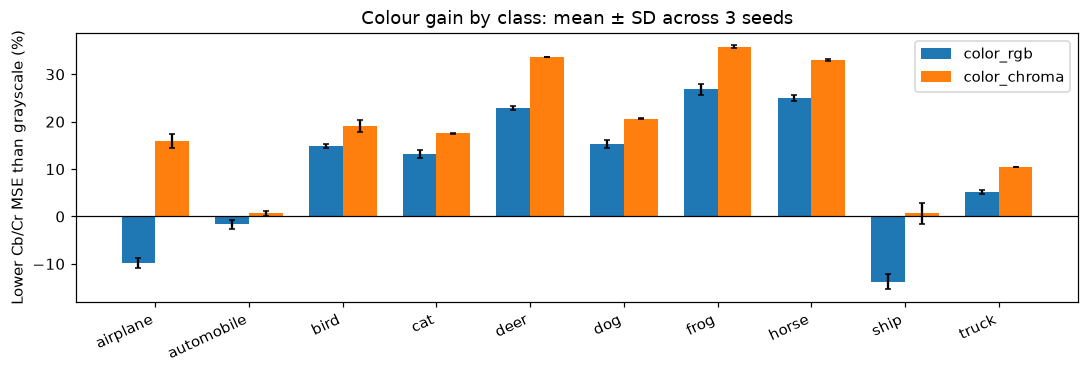

In [10]:
def chrominance(rgb):
    luminance = grayscale(rgb)
    return torch.cat([(rgb[:, 2:3] - luminance) / 1.772,
                      (rgb[:, 0:1] - luminance) / 1.402], dim=1)

@torch.no_grad()
def colour_diagnostics(model, task):
    values = {key: [] for key in ["rgb_mse", "luma_mse", "cbcr_mse", "chroma_magnitude"]}
    for batch in test_rgb.split(BATCH_SIZE):
        prediction = (grayscale(batch).expand(-1, 3, -1, -1) if model is None
                      else predict_rgb(model, batch, task))
        predicted_chroma = chrominance(prediction)
        values["rgb_mse"].append((prediction-batch).square().mean((1, 2, 3)).cpu())
        values["luma_mse"].append((grayscale(prediction)-grayscale(batch)).square().mean((1, 2, 3)).cpu())
        values["cbcr_mse"].append((predicted_chroma-chrominance(batch)).square().mean((1, 2, 3)).cpu())
        values["chroma_magnitude"].append(predicted_chroma.square().sum(1).sqrt().mean((1, 2)).cpu())
    return {key: torch.cat(parts).numpy() for key, parts in values.items()}

target_chroma_magnitude = float(chrominance(test_rgb).square().sum(1).sqrt().mean().cpu())
gray_diagnostics = colour_diagnostics(None, "gray_copy")
diagnostic_runs, diagnostic_classes = [], []

def collect_diagnostics(name, seed, values):
    row = {"name": name, "seed": seed}
    row.update({key: float(value.mean()) for key, value in values.items()})
    row["relative_chroma_pct"] = 100 * row["chroma_magnitude"] / target_chroma_magnitude
    diagnostic_runs.append(row)
    for label, class_name in enumerate(class_names):
        mask = test_labels == label
        diagnostic_classes.append({
            "name": name, "seed": seed, "class": class_name, "count": int(mask.sum()),
            "cbcr_mse": float(values["cbcr_mse"][mask].mean()),
            "gray_cbcr_mse": float(gray_diagnostics["cbcr_mse"][mask].mean()),
            "gain_pct": 100 * (1 - float(values["cbcr_mse"][mask].mean()) /
                                float(gray_diagnostics["cbcr_mse"][mask].mean())),
        })

collect_diagnostics("gray_copy", -1, gray_diagnostics)
for config in color_configs:
    for seed in SEEDS:
        model = load_run(config, seed)
        values = colour_diagnostics(model, config["task"])
        collect_diagnostics(config["name"], seed, values)
        del model
diagnostic_runs = pd.DataFrame(diagnostic_runs)
diagnostic_summary = diagnostic_runs.groupby("name", sort=False).agg(
    rgb_mse=("rgb_mse", "mean"), luma_mse=("luma_mse", "mean"),
    cbcr_mse=("cbcr_mse", "mean"), cbcr_mse_sd=("cbcr_mse", "std"),
    relative_chroma_pct=("relative_chroma_pct", "mean"),
    relative_chroma_pct_sd=("relative_chroma_pct", "std"),
).fillna(0).reset_index()
diagnostic_classes = pd.DataFrame(diagnostic_classes)
diagnostic_runs.to_csv(RESULTS / "color_diagnostics_runs.csv", index=False)
diagnostic_summary.to_csv(RESULTS / "color_diagnostics_summary.csv", index=False)
diagnostic_classes.to_csv(RESULTS / "color_diagnostics_by_class.csv", index=False)
display(diagnostic_summary.round(6))

fig, ax = plt.subplots(figsize=(10, 3.5))
for offset, name in [(-0.18, "color_rgb"), (0.18, "color_chroma")]:
    grouped = diagnostic_classes[diagnostic_classes.name == name].groupby("class").gain_pct
    means = grouped.mean().reindex(class_names)
    deviations = grouped.std().reindex(class_names)
    ax.bar(np.arange(10)+offset, means, width=0.36, yerr=deviations, capsize=2, label=name)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(np.arange(10), class_names, rotation=25, ha="right")
ax.set(ylabel="Lower Cb/Cr MSE than grayscale (%)",
       title="Colour gain by class: mean ± SD across 3 seeds")
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / "color_gain_by_class.png", dpi=180, bbox_inches="tight")
plt.show()

## 11. Conclusion

Baseline test MSE: **0.005629**; validation-selected reconstruction: **spatial16** (**0.002314**).

Width and spatial resolution are separate experiments. The spatial contrast holds learned parameter count fixed; structural contrasts keep latent shape fixed. Spatial16 has a 4,096-value central code but still a 2,048-value encoder bottleneck.

Validation selects **color_chroma** for colourisation: **19.9% lower** test MSE than grayscale copying. It reaches **49.8%** of target chroma magnitude. Direct RGB learns some colour despite higher total RGB MSE. Three seeds and one reused test split limit generalisation.

## References
- *Lab - CAE.pdf*, Exercises 1–3.
- Krizhevsky (2009), *Learning Multiple Layers of Features from Tiny Images*; CIFAR-10.
- Torchvision CIFAR10 and PyTorch documentation.
- Optional mirror: https://huggingface.co/datasets/uoft-cs/cifar10.

Restart the kernel and Run All to reuse compatible checkpoints. Set `RETRAIN=True` for fresh training.